In [2]:
import pandas as pd
import requests
from bs4 import BeautifulSoup

# if 403 bad request error occurs then add headers to the requests

headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 6.3; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/80.0.3987.162 Safari/537.36'}


In [3]:
headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 6.3; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/80.0.3987.162 Safari/537.36'}
webpage = requests.get("https://www.ambitionbox.com/list-of-companies?campaign=desktop_nav&page=2", headers=headers).text

In [4]:
soup = BeautifulSoup(webpage, 'lxml')

<!DOCTYPE html>
<html lang="en">
 <head>
  <meta charset="utf-8"/>
  <title>
   Top Companies in India | AmbitionBox
  </title>
  <meta content="Top Companies in India | AmbitionBox" name="title"/>
  <meta content="Get detailed information of top Companies in India shared by employees through reviews, salaries, interview questions, benefits and more." name="description"/>
  <meta content="width=device-width,initial-scale=1, minimum-scale=1, interactive-widget=resizes-content" name="viewport"/>
  <link href="https://static.ambitionbox.com/alpha/img/supporting-images/browser_icon_16x16.png" rel="icon" sizes="16x16" type="image/png"/>
  <link href="https://static.ambitionbox.com/alpha/img/supporting-images/browser_icon_32x32.png" rel="icon" sizes="32x32" type="image/png"/>
  <link href="https://static.ambitionbox.com/alpha/img/supporting-images/browser_icon_48x48.png" rel="icon" sizes="48x48" type="image/png"/>
  <link href="https://static.ambitionbox.com/alpha/img/supporting-images/brows
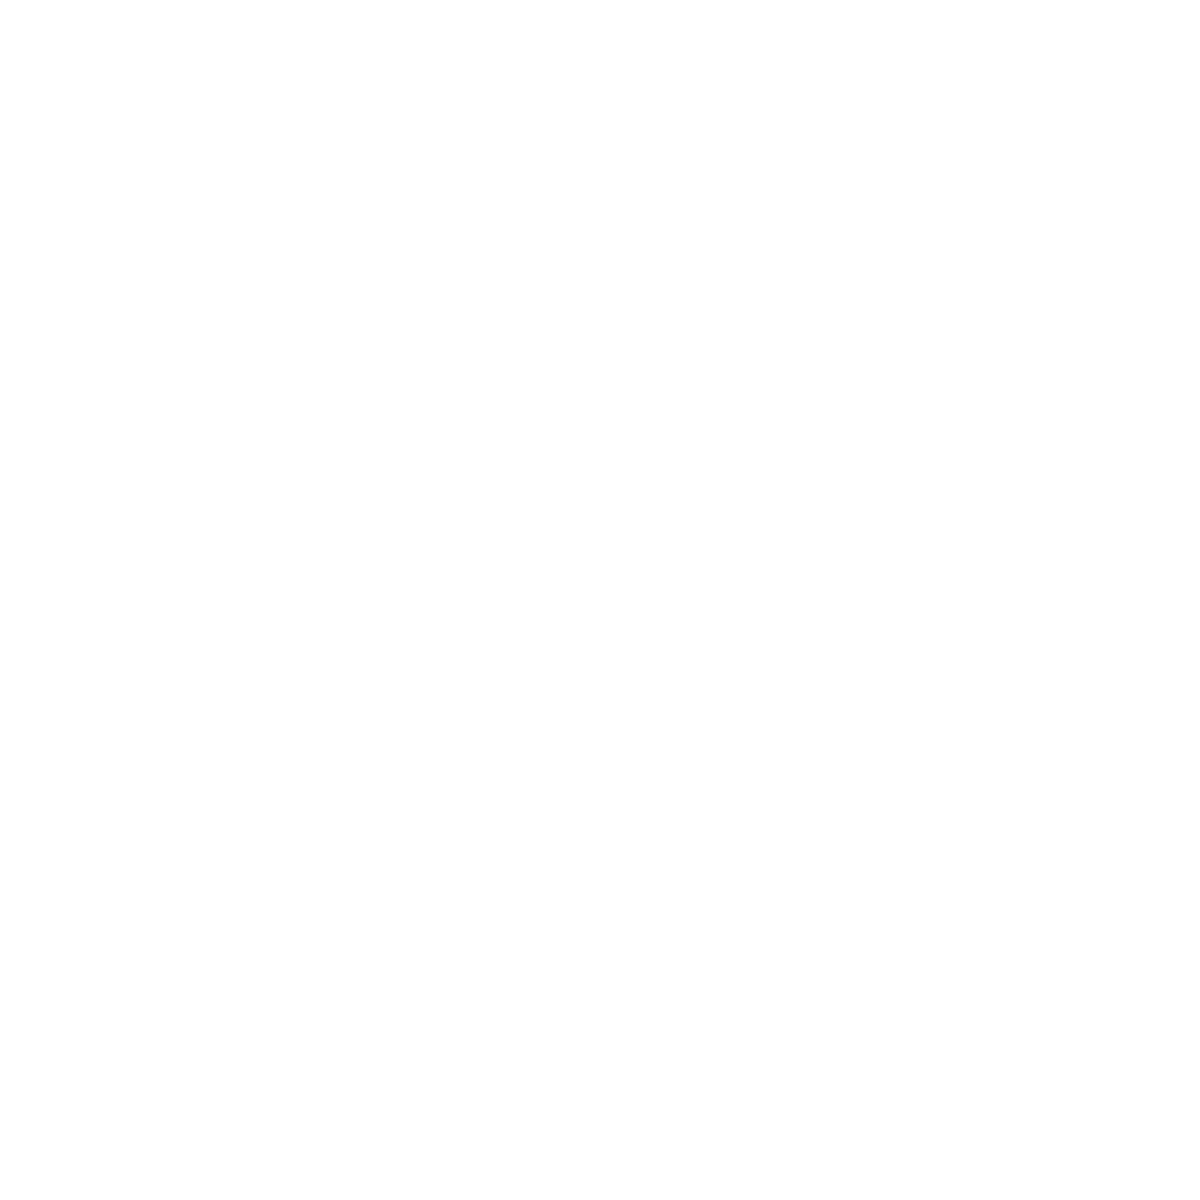

In [5]:
print(soup.prettify()) # prettify() function returns the HTML structure of the data

In [6]:
soup.find_all('h1')[0]

<h1 class="m-0 text-2xl font-pn-700 leading-8 text-primary-text max-md:text-[20px] max-md:leading-7" data-testid="loc-page-heading">List of companies in India</h1>

In [7]:
soup.find_all('h1')[0].text

'List of companies in India'

In [8]:
for i in soup.find_all('h2'):
    print(i.text.strip())

print(len(soup.find_all('h2')))

IBM
Larsen & Toubro Limited
Deloitte
Kotak Mahindra Bank
Reliance Industries
Bharti Airtel
Vodafone Idea
WNS
IDFC FIRST Bank
BYJU'S
Ernst & Young
IndusInd Bank
AU Small Finance Bank
Tata Motors
Bajaj Finserv
Flipkart
PwC
Muthoot FinCorp
Mahindra & Mahindra
HDFC Life
20


In [9]:
for i in soup.find_all('span'):
    print(i.text.strip())

Login
Home
Companies
Reviews
Salaries
Interview Questions
Jobs
Tools
Compare Companies
Salary Calculator
Are you paid fairly?
Evaluate Offer Letter
Gratuity Calculator
HRA Calculator
Salary Hike Calculator
Awards
ABECA 2027
Rate Now
ABECA 2026
ABECA 2025
Communities
FOR EMPLOYERS
Create Company Profile
Edit Company Profile
Respond to reviews
Invite employees to review
Employer Offerings
Employer Brochure
More
About Us
Our Team
Email Us
Privacy
Grievances
Terms of Use
Community Guidelines
Credits
Summons/Notices
Blog
FAQ
Browser ExtensionNEW
Browser Extension
All Filters
Follow
3.9
(27.7k)
IT Services & Consulting | Bengaluru +180 other locations
Highly Rated For
Work Life Balance, Company Culture, Job Security
Critically Rated For
Promotions, Salary
27.7k
Reviews
2.2L
Salaries
2.7k
Interviews
949
Jobs
2.7k
Benefits
24
Photos
Follow
3.9
(26.7k)
Engineering & Construction | Mumbai +844 other locations
Highly Rated For
Job Security, Skill Development, Salary
Critically Rated For
Promotion

In [13]:
soup.find_all('span', class_='text-primary-text')

[<span class="text-primary-text font-pn-700 text-sm !text-[14px] !leading-[14px]">3.9</span>,
 <span class="text-primary-text font-pn-700 text-sm !text-[14px] !leading-[14px]">3.9</span>,
 <span class="text-primary-text font-pn-700 text-sm !text-[14px] !leading-[14px]">3.6</span>,
 <span class="text-primary-text font-pn-700 text-sm !text-[14px] !leading-[14px]">3.6</span>,
 <span class="text-primary-text font-pn-700 text-sm !text-[14px] !leading-[14px]">4.0</span>,
 <span class="text-primary-text font-pn-700 text-sm !text-[14px] !leading-[14px]">3.8</span>,
 <span class="text-primary-text font-pn-700 text-sm !text-[14px] !leading-[14px]">3.9</span>,
 <span class="text-primary-text font-pn-700 text-sm !text-[14px] !leading-[14px]">3.3</span>,
 <span class="text-primary-text font-pn-700 text-sm !text-[14px] !leading-[14px]">4.0</span>,
 <span class="text-primary-text font-pn-700 text-sm !text-[14px] !leading-[14px]">3.2</span>,
 <span class="text-primary-text font-pn-700 text-sm !text-[1

In [14]:
len(soup.find_all('span', class_="pl-1"))

20

In [15]:
company = soup.find_all('div', class_='flex cursor-pointer px-5 pt-5 gap-2 max-md:px-3 max-md:pt-4')

In [19]:
name=[]
ratings=[]
reviews=[]

for i in company:
    name.append(i.find('h2').text.strip())
    ratings.append(i.find('span', class_='text-primary-text').text.strip())
    reviews.append(i.find('span', class_='pl-1').text.strip())


d = {'name': name, 'rating': ratings, 'reviews': reviews}

df = pd.DataFrame(d)

In [20]:
df

,name,rating,reviews
0,IBM,3.9,(27.7k)
1,Larsen & Toubro Limited,3.9,(26.7k)
2,Deloitte,3.6,(26k)
3,Kotak Mahindra Bank,3.6,(24.5k)
4,Reliance Industries,4.0,(22.2k)
5,Bharti Airtel,3.8,(18.8k)
6,Vodafone Idea,3.9,(18.7k)
7,WNS,3.3,(16.8k)
8,IDFC FIRST Bank,4.0,(16.7k)
9,BYJU'S,3.2,(16.6k)


In [21]:
final = pd.DataFrame()

for j in range(1, 11):

    url = f"https://www.ambitionbox.com/list-of-companies?campaign=desktop_nav&page={j}"

    headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 6.3; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/80.0.3987.162 Safari/537.36'}
    webpage = requests.get(url, headers=headers).text

    soup = BeautifulSoup(webpage, 'lxml')

    company = soup.find_all('div', class_='flex cursor-pointer px-5 pt-5 gap-2 max-md:px-3 max-md:pt-4')

    name=[]
    ratings=[]
    reviews=[]
    
    for i in company:
        name.append(i.find('h2').text.strip())
        ratings.append(i.find('span', class_='text-primary-text').text.strip())
        reviews.append(i.find('span', class_='pl-1').text.strip())
    
    
    d = {'name': name, 'rating': ratings, 'reviews': reviews}
    
    df = pd.DataFrame(d)

    final = pd.concat([final,df], ignore_index=True)

    

In [22]:
final

,name,rating,reviews
0,TCS,3.2,(1.2L)
1,Accenture,3.7,(80.1k)
2,Wipro,3.6,(70.3k)
3,Cognizant,3.7,(66.3k)
4,Capgemini,3.6,(58.3k)
...,...,...,...
195,PNB MetLife,3.3,(4.4k)
196,Tata Communications,3.8,(4.3k)
197,Publicis Sapient,3.2,(4.3k)
198,Pidilite Industries,4.2,(4.3k)
